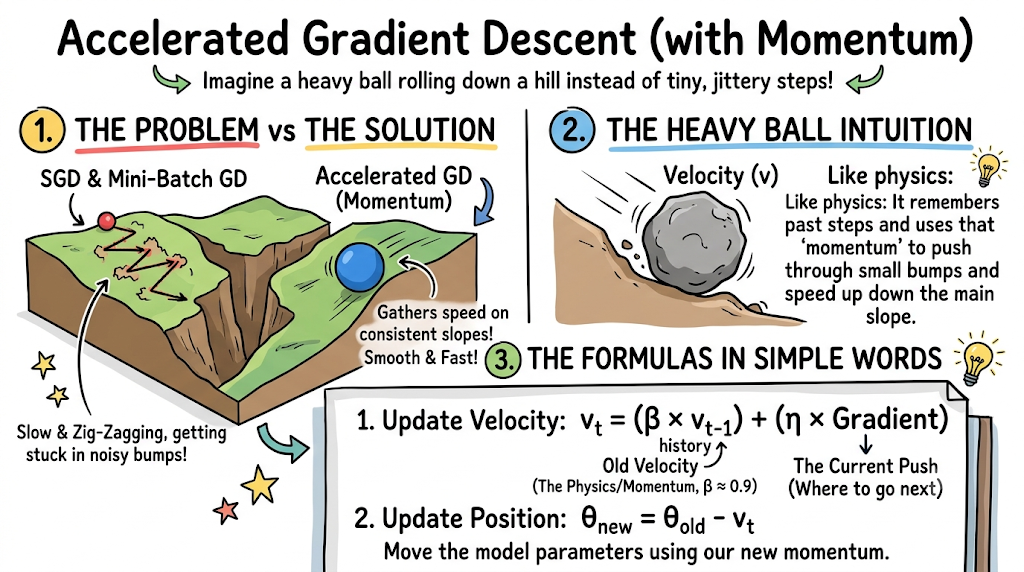


The Beale Function

min f(x,y)=(1.5-x+xy)^{2}+(2.25-x+xy^{2})^{2}+(2.625-x+xy^{3})^{2}

In [37]:
import numpy as np
import matplotlib.pyplot as plt

In [38]:
#2D

#our height Z
def f(x,y):
    return (1.5 - x + x*y)**2 + (2.25 - x + x*(y**2))**2 + (2.625 - x + x*(y**3))**2

#our gradients:
def grad_f(x,y):
    df_dx = 2*(1.5 - x + x*y)*(y-1) + 2*(2.25 - x + x*(y**2))*(y**2 - 1) + 2*(2.625 - x + x*(y**3))*(y**3 - 1)
    df_dy = 2*(1.5 - x + x*y)*(x) + 2*(2.25 - x + x*(y**2))*(2*x*y) + 2*(2.625 - x + x*(y**3))*(3*x*(y**2))
    return np.array([df_dx, df_dy])

#current points / knobs
point = np.array([0.5,0.5])
k=0
max_iter=1000
tol=1e-6
alpha=0.01 #or N 


history_of_x = [point[0]]
history_of_y = [point[1]]
history_of_z = [f(point[0], point[1])]

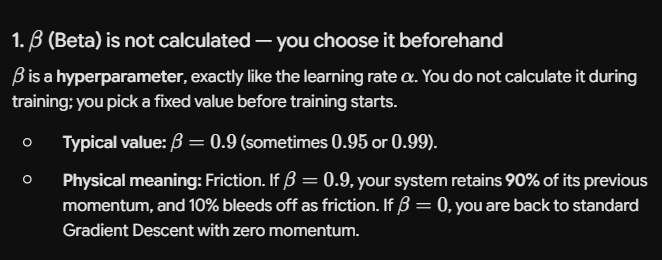

In [39]:
#new beta
beta = 0.9

#new velocity
v = 0

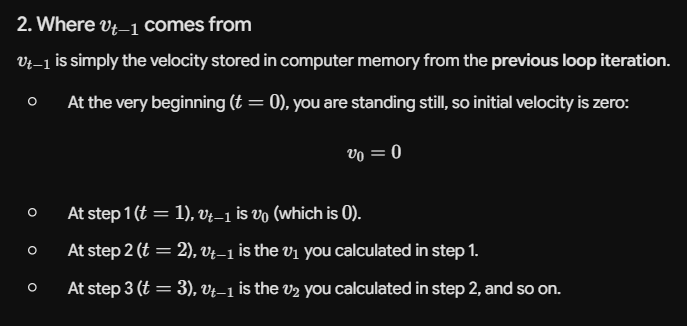

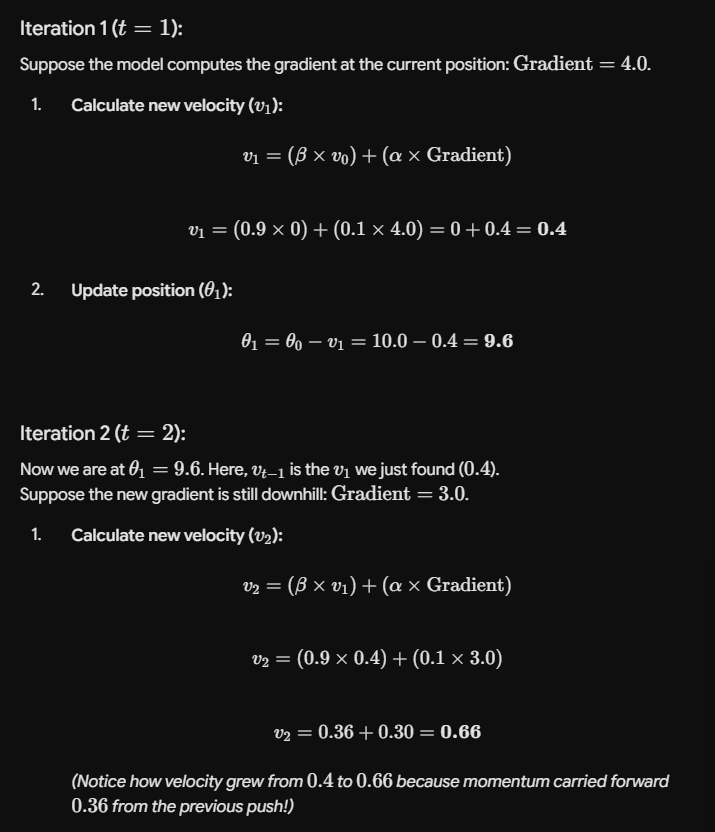

In [40]:
while np.linalg.norm(grad_f(point[0],point[1]))>tol and max_iter > k:

    #gradient:
    gradient = grad_f(point[0], point[1])

    #calculate veloctity:
    v1 = (beta * v) + (alpha * gradient)

    #new position:
    new_pos = point - v1

    #update:
    v=v1
    point = new_pos

    k +=1

    history_of_x.append(point[0])
    history_of_y.append(point[1])
    history_of_z.append(f(point[0], point[1]))

    print(f'[Epoch {k}]: Current Height {f(point[0], point[1])}, Current Points: {point}')


[Epoch 1]: Current Height 9.01050317914844, Current Points: [0.57890625 0.45234375]
[Epoch 2]: Current Height 7.408181264718128, Current Points: [0.72945328 0.36208918]
[Epoch 3]: Current Height 5.33215156287244, Current Points: [0.94300287 0.23761417]
[Epoch 4]: Current Height 3.29227711620493, Current Points: [1.20621407 0.09325045]
[Epoch 5]: Current Height 1.8407969747294177, Current Points: [ 1.49974617 -0.05211466]
[Epoch 6]: Current Height 1.3075089725638753, Current Points: [ 1.79983535 -0.17852318]
[Epoch 7]: Current Height 1.6437438206789001, Current Points: [ 2.08149311 -0.26621331]
[Epoch 8]: Current Height 2.350602342644849, Current Points: [ 2.32237399 -0.29531734]
[Epoch 9]: Current Height 2.693877033928004, Current Points: [ 2.50745214 -0.2508382 ]
[Epoch 10]: Current Height 2.3050025434700547, Current Points: [ 2.63280046 -0.13198824]
[Epoch 11]: Current Height 1.3626548036732453, Current Points: [2.70520131 0.04827812]
[Epoch 12]: Current Height 0.3334989667756849, Cu

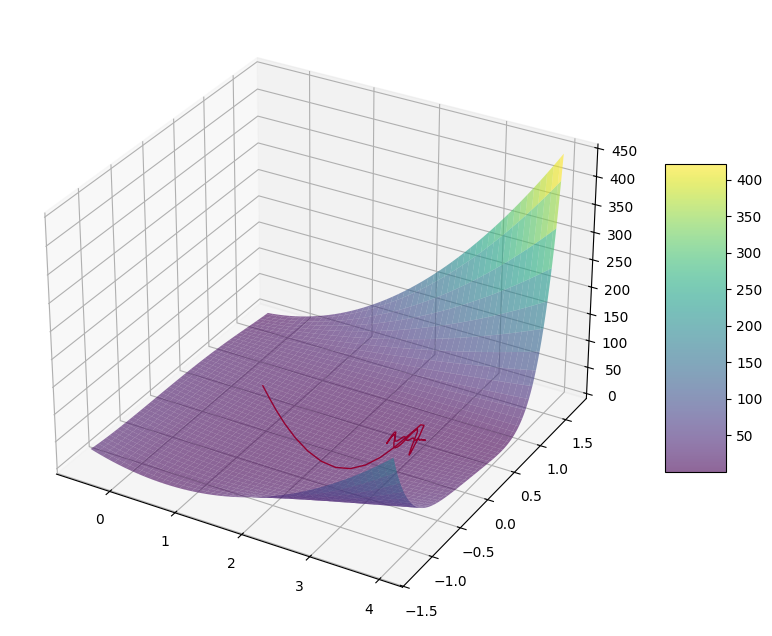

In [44]:
X_surf = np.linspace(min(history_of_x)-1,max(history_of_x)+1,100)
Y_surf = np.linspace(min(history_of_y)-1,max(history_of_y)+1,100)
X,Y = np.meshgrid(X_surf, Y_surf)
Z = f(X,Y)

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(projection='3d')

surf = ax.plot_surface(X,Y,Z,cmap='viridis', alpha=0.6) #the 3d land
fig.colorbar(surf, ax=ax, shrink= 0.5, aspect=5)

ax.plot(history_of_x,history_of_y,history_of_z, color = 'Red', marker='', linewidth = 1,label='AGD Path') #add a marker if want

plt.show()

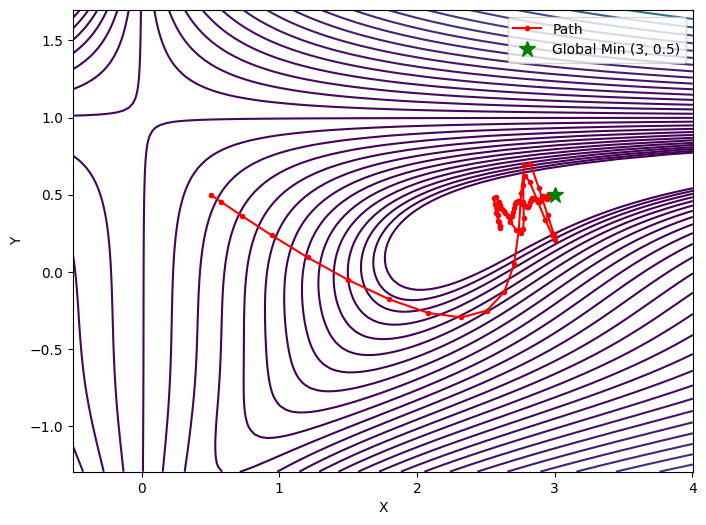

In [48]:
fig,ax = plt.subplots(figsize = (8,6))
cp = ax.contour(X,Y,Z, levels=np.logspace(0, 3, 35),cmap='viridis')
ax.plot(history_of_x, history_of_y, 'ro-', linewidth=1.5, markersize=3, label='Path')
ax.plot(3.0, 0.5, 'g*', markersize=12, label='Global Min (3, 0.5)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.legend()
plt.show()